# KNN-Graph-Based Clustering of Wholesale Customers
## Machine Learning Lab Experiment

### Aim
To group wholesale customers using a nearest-neighbor graph and evaluate the resulting clusters using numerical metrics and visualizations.

### Method note
KNN usually refers to a supervised prediction algorithm, so it is not itself a standard clustering algorithm. This experiment uses a **k-nearest-neighbor graph** to represent local similarities between customers, then applies **Spectral Clustering** to partition that graph. This is a defensible unsupervised, nearest-neighbor-based clustering workflow.

### Objectives
- Inspect and prepare the wholesale customer spending data.
- Transform and scale spending features so large numerical ranges do not dominate distance calculations.
- Construct nearest-neighbor relationships and compare candidate cluster counts.
- Evaluate clusters using silhouette score and cluster-size summaries.
- Visualize and interpret the customer groups.

## 1. Dataset and libraries

The supplied file is `Wholesale customers data.csv`. It contains customer records, two categorical descriptors (`Channel` and `Region`), and six annual spending measures. The six spending measures are used to build the clustering representation. `Channel` and `Region` are retained for later descriptive interpretation and are not used as clustering inputs.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import kneighbors_graph
from sklearn.cluster import SpectralClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 20)

DATA_PATH = "Wholesale customers data.csv"
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (440, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


None

## 2. Initial inspection
Check data types, missing values, duplicates, and basic distributions before applying distance-based methods.

In [2]:
print("Column types:")
display(df.dtypes.rename("dtype").to_frame())
print("\\nMissing values per column:")
display(df.isna().sum().rename("missing_values").to_frame())
print("Exact duplicate rows:", df.duplicated().sum())
display(df.describe().T.round(2))

Column types:
\nMissing values per column:
Exact duplicate rows: 0


,dtype
Channel,int64
Region,int64
Fresh,int64
Milk,int64
Grocery,int64
Frozen,int64
Detergents_Paper,int64
Delicassen,int64


,missing_values
Channel,0
Region,0
Fresh,0
Milk,0
Grocery,0
Frozen,0
Detergents_Paper,0
Delicassen,0


,count,mean,std,min,25%,50%,75%,max
Channel,440.0,1.32,0.47,1.0,1.00,1.0,2.00,2.0
Region,440.0,2.54,0.77,1.0,2.00,3.0,3.00,3.0
Fresh,440.0,12000.30,12647.33,3.0,3127.75,8504.0,16933.75,112151.0
Milk,440.0,5796.27,7380.38,55.0,1533.00,3627.0,7190.25,73498.0
Grocery,440.0,7951.28,9503.16,3.0,2153.00,4755.5,10655.75,92780.0
Frozen,440.0,3071.93,4854.67,25.0,742.25,1526.0,3554.25,60869.0
Detergents_Paper,440.0,2881.49,4767.85,3.0,256.75,816.5,3922.00,40827.0
Delicassen,440.0,1524.87,2820.11,3.0,408.25,965.5,1820.25,47943.0


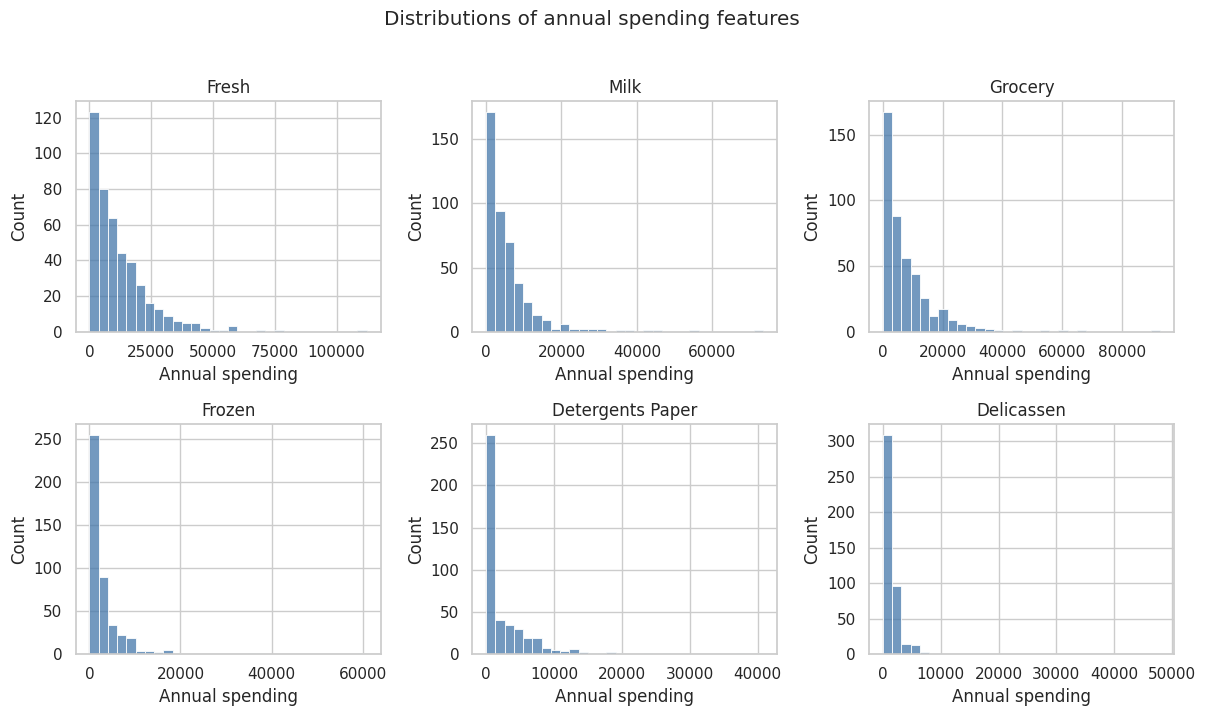

In [3]:
spend_cols = [
    "Fresh", "Milk", "Grocery", "Frozen",
    "Detergents_Paper", "Delicassen"
]
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, col in zip(axes.flat, spend_cols):
    sns.histplot(df[col], bins=30, ax=ax, color="#4477AA")
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("Annual spending")
plt.suptitle("Distributions of annual spending features", y=1.02)
plt.tight_layout()
plt.show()

## 3. Data preparation

Spending amounts are strongly right-skewed and measured on different ranges. A `log1p` transform reduces skew while safely handling zero values. Standardization then gives each spending category a comparable scale for distance calculations. The two categorical descriptors are not included in the distance calculation.

In [4]:
X_raw = df[spend_cols].copy()
X_log = np.log1p(X_raw)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Rows used:", X_scaled.shape[0])
print("Spending features used:", spend_cols)
print("Missing values in clustering features:", X_raw.isna().sum().sum())
print("Mean of scaled features (approximately 0):", np.round(X_scaled.mean(axis=0), 3))
print("Standard deviation (approximately 1):", np.round(X_scaled.std(axis=0), 3))

Rows used: 440
Spending features used: ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Missing values in clustering features: 0
Mean of scaled features (approximately 0): [ 0. -0. -0.  0. -0. -0.]
Standard deviation (approximately 1): [1. 1. 1. 1. 1. 1.]


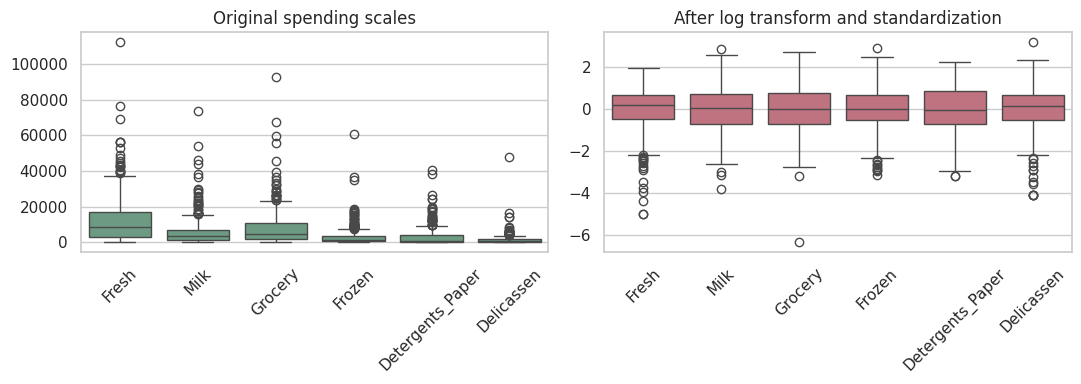

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.boxplot(data=X_raw, ax=axes[0], color="#66A182")
axes[0].set_title("Original spending scales")
axes[0].tick_params(axis="x", rotation=45)
sns.boxplot(data=pd.DataFrame(X_scaled, columns=spend_cols), ax=axes[1], color="#CC6677")
axes[1].set_title("After log transform and standardization")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

## 4. Build the nearest-neighbor graph

Each customer is connected to its nearest neighbors in the prepared feature space. The graph encodes local similarity rather than assuming that clusters must be spherical around centroids. Spectral Clustering uses this nearest-neighbor affinity structure to assign customers to clusters.

In [6]:
n_neighbors = 10
knn_graph = kneighbors_graph(
    X_scaled,
    n_neighbors=n_neighbors,
    mode="connectivity",
    include_self=False
)
print("Number of customers:", knn_graph.shape[0])
print("Neighbors per customer:", n_neighbors)
print("Directed graph connections:", knn_graph.nnz)
print("Graph density:", round(knn_graph.nnz / (knn_graph.shape[0] * (knn_graph.shape[0] - 1)), 4))

Number of customers: 440
Neighbors per customer: 10
Directed graph connections: 4400
Graph density: 0.0228


## 5. Compare candidate cluster counts

The number of clusters is not known in advance. We test values from 2 to 6 while holding the neighbor count at 10. Silhouette score measures how well-separated the resulting groups are in the transformed, scaled feature space. It is used as a diagnostic, not as proof that one grouping is objectively correct.

In [7]:
results = []
labels_by_k = {}
for n_clusters in range(2, 7):
    model = SpectralClustering(
        n_clusters=n_clusters,
        affinity="nearest_neighbors",
        n_neighbors=n_neighbors,
        assign_labels="kmeans",
        random_state=42
    )
    labels = model.fit_predict(X_scaled)
    labels_by_k[n_clusters] = labels
    score = silhouette_score(X_scaled, labels)
    sizes = pd.Series(labels).value_counts().sort_index()
    results.append({
        "clusters": n_clusters,
        "silhouette_score": score,
        "smallest_cluster": int(sizes.min()),
        "largest_cluster": int(sizes.max()),
        "number_of_nonempty_clusters": int(sizes.size)
    })

scores_df = pd.DataFrame(results)
display(scores_df.round(4))

,clusters,silhouette_score,smallest_cluster,largest_cluster,number_of_nonempty_clusters
0,2,0.2887,181,259,2
1,3,0.1979,76,212,3
2,4,0.1785,64,220,4
3,5,0.1630,53,132,5
4,6,0.1502,46,128,6


Best tested cluster count by silhouette score: 2


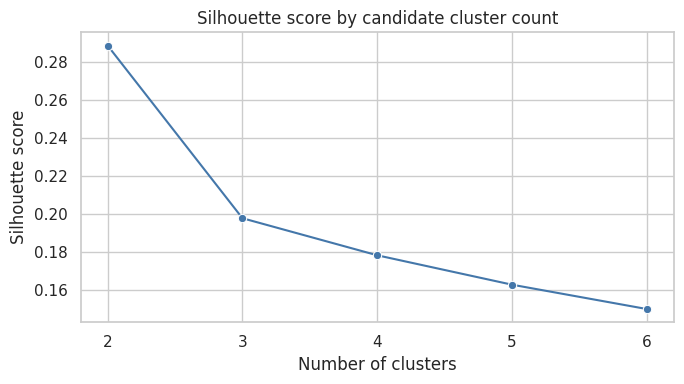

In [8]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.lineplot(data=scores_df, x="clusters", y="silhouette_score", marker="o", ax=ax, color="#4477AA")
ax.set_title("Silhouette score by candidate cluster count")
ax.set_xlabel("Number of clusters")
ax.set_ylabel("Silhouette score")
ax.set_xticks(range(2, 7))
plt.tight_layout()
plt.show()

best_k = int(scores_df.loc[scores_df["silhouette_score"].idxmax(), "clusters"])
print("Best tested cluster count by silhouette score:", best_k)

## 6. Inspect the selected clustering

We use the candidate count with the highest silhouette score among those tested. Cluster IDs are arbitrary labels and do not imply a ranking. We examine group sizes and mean annual spending to understand how the clusters differ.

In [9]:
best_labels = labels_by_k[best_k]
clustered = df.copy()
clustered["Cluster"] = best_labels

print("Customer count per cluster:")
display(clustered["Cluster"].value_counts().sort_index().rename("customers").to_frame())

cluster_means = clustered.groupby("Cluster")[spend_cols].mean().round(1)
display(cluster_means)

Customer count per cluster:


,customers
Cluster,
0,181
1,259


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Cluster,,,,,,
0,9997.3,10422.0,15048.7,2273.7,6289.3,2248.0
1,13400.1,2563.6,2991.3,3629.8,500.0,1019.5


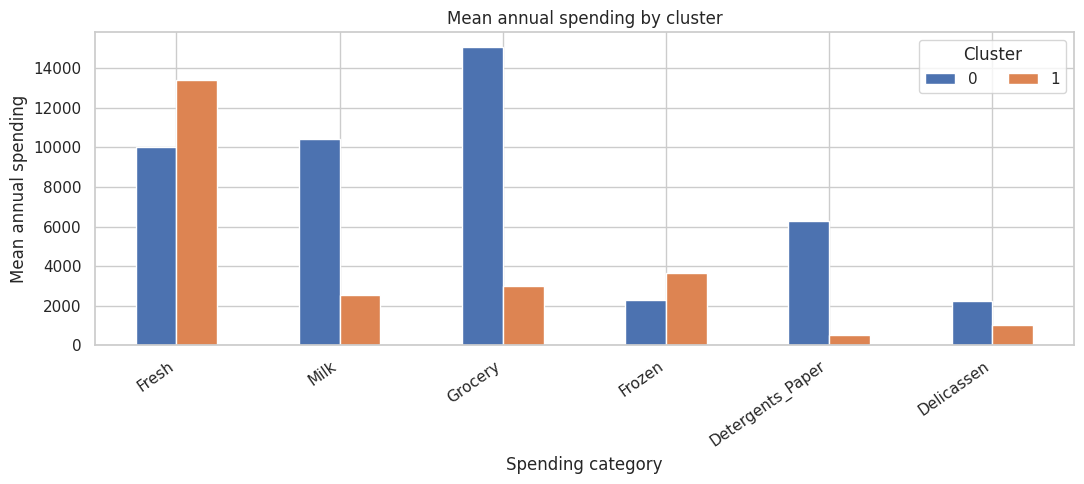

In [10]:
cluster_means.T.plot(kind="bar", figsize=(11, 5))
plt.title("Mean annual spending by cluster")
plt.xlabel("Spending category")
plt.ylabel("Mean annual spending")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Cluster", ncol=2)
plt.tight_layout()
plt.show()

## 7. Two-dimensional visualization with PCA

PCA compresses the six standardized spending features into two dimensions for plotting. The visualization is only a projection: some distances and separations in six dimensions may not be preserved perfectly in two dimensions.

Variance explained by first two components: 0.713


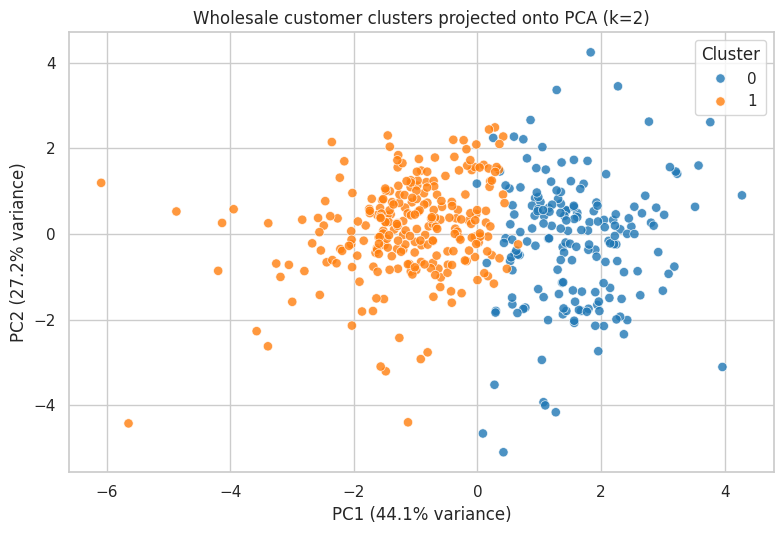

In [11]:
pca = PCA(n_components=2, random_state=42)
X_2d = pca.fit_transform(X_scaled)
plot_df = pd.DataFrame({
    "PC1": X_2d[:, 0],
    "PC2": X_2d[:, 1],
    "Cluster": best_labels.astype(str)
})
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="Cluster", palette="tab10", s=45, alpha=0.8, ax=ax)
ax.set_title(f"Wholesale customer clusters projected onto PCA (k={best_k})")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.tight_layout()
plt.show()
print("Variance explained by first two components:", round(pca.explained_variance_ratio_.sum(), 3))

## 8. Descriptive interpretation

The `Channel` and `Region` fields were excluded from clustering, but can help describe the resulting groups. These summaries are post-hoc descriptions only; they did not determine cluster membership.

In [12]:
print("Channel composition within clusters (row proportions):")
display(pd.crosstab(clustered["Cluster"], clustered["Channel"], normalize="index").round(3))
print("Region composition within clusters (row proportions):")
display(pd.crosstab(clustered["Cluster"], clustered["Region"], normalize="index").round(3))

Channel composition within clusters (row proportions):
Region composition within clusters (row proportions):


Channel,1,2
Cluster,,
0,0.254,0.746
1,0.973,0.027


Region,1,2,3
Cluster,,,
0,0.149,0.099,0.751
1,0.193,0.112,0.695


In [13]:
summary = clustered.groupby("Cluster").agg(
    customers=("Cluster", "size"),
    mean_fresh=("Fresh", "mean"),
    mean_milk=("Milk", "mean"),
    mean_grocery=("Grocery", "mean"),
    mean_frozen=("Frozen", "mean"),
    mean_detergents_paper=("Detergents_Paper", "mean"),
    mean_delicassen=("Delicassen", "mean")
).round(1)
display(summary)

,customers,mean_fresh,mean_milk,mean_grocery,mean_frozen,mean_detergents_paper,mean_delicassen
Cluster,,,,,,,
0,181,9997.3,10422.0,15048.7,2273.7,6289.3,2248.0
1,259,13400.1,2563.6,2991.3,3629.8,500.0,1019.5


## 9. Results and discussion

The experiment applies nearest-neighbor graph construction followed by Spectral Clustering. Preprocessing is essential because Euclidean neighborhoods are sensitive to feature scales and highly skewed spending distributions. The silhouette comparison provides a consistent basis for selecting a candidate cluster count from the tested range.

### Limitations
- The number of clusters and neighbor count influence the results.
- Spectral Clustering can be sensitive to the graph structure and dataset geometry.
- Silhouette score evaluates separation in the scaled feature space, not business usefulness.
- The customer records are not time-series observations, so changes over time cannot be inferred.
- Cluster labels are arbitrary. Business labels should be assigned only after inspecting the spending profiles.

## 10. Conclusion

The Wholesale Customers dataset was prepared using log transformation and standardization, then represented as a nearest-neighbor graph. Spectral Clustering was applied to that graph, and candidate cluster counts were compared using silhouette scores. Cluster-size summaries, spending profiles, a PCA scatter plot, and post-hoc channel and region summaries were used to interpret the results.

This is a **nearest-neighbor graph clustering experiment**, rather than supervised KNN classification. The results demonstrate how local neighbor relationships can support unsupervised grouping of customers.